In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

In [2]:
np.random.seed(42)

In [3]:
data = load_breast_cancer()

In [5]:
X = pd.DataFrame(data.data, columns = data.feature_names)
y = data.target

In [6]:
X.shape

(569, 30)

In [7]:
np.unique(y)

array([0, 1])

In [8]:
X.columns.tolist()

['mean radius',
 'mean texture',
 'mean perimeter',
 'mean area',
 'mean smoothness',
 'mean compactness',
 'mean concavity',
 'mean concave points',
 'mean symmetry',
 'mean fractal dimension',
 'radius error',
 'texture error',
 'perimeter error',
 'area error',
 'smoothness error',
 'compactness error',
 'concavity error',
 'concave points error',
 'symmetry error',
 'fractal dimension error',
 'worst radius',
 'worst texture',
 'worst perimeter',
 'worst area',
 'worst smoothness',
 'worst compactness',
 'worst concavity',
 'worst concave points',
 'worst symmetry',
 'worst fractal dimension']

In [9]:
X.isnull().sum().sum()

0

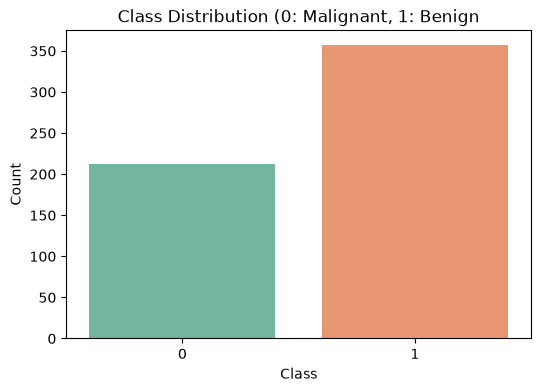

In [11]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y, palette = 'Set2')
plt.title('Class Distribution (0: Malignant, 1: Benign')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

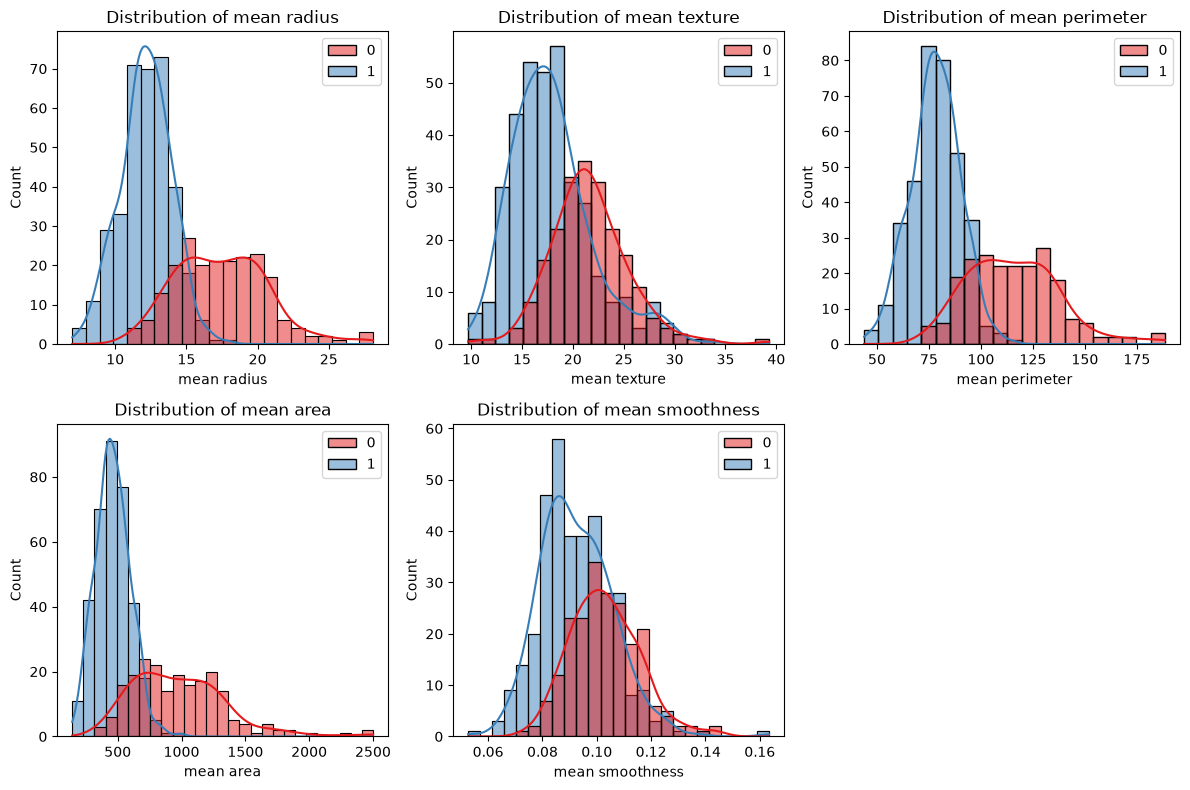

In [13]:
plt.figure(figsize = (12, 8))
for i, feature in enumerate(X.columns[:5]):
    plt.subplot(2, 3, i+1)
    sns.histplot(data=X, x=feature, hue=y, kde=True, palette='Set1')
    plt.title(f'Distribution of {feature}')
    plt.tight_layout()
plt.show()

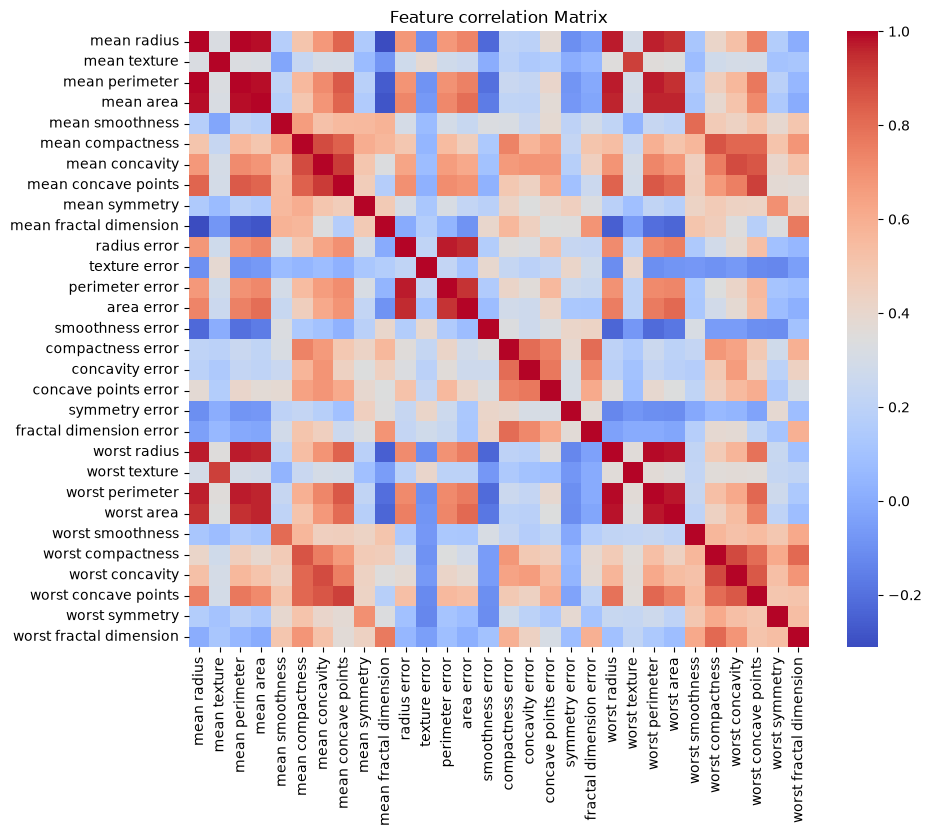

In [15]:
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), cmap='coolwarm', annot=False)
plt.title('Feature correlation Matrix')
plt.show()

In [18]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

In [19]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(f"Explained Variance Ratio by PCA: {pca.explained_variance_ratio_}")

Explained Variance Ratio by PCA: [0.44272026 0.18971182]


In [22]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)
print("\nTraining Set Shape:", X_train.shape)
print("Testing Set Shape:", X_test.shape)


Training Set Shape: (455, 30)
Testing Set Shape: (114, 30)


In [23]:
svc = SVC(kernel = 'rbf', random_state = 42)
svc.fit(X_train, y_train)
print("\nInitial SVC Model Trained (Default Parameters)")


Initial SVC Model Trained (Default Parameters)


In [24]:
y_train_pred = svc.predict(X_train)
y_test_pred = svc.predict(X_test)

In [25]:
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
print("\nInitial Model Evaluation:")
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


Initial Model Evaluation:
Training Accuracy: 0.9824
Test Accuracy: 0.9825


In [26]:
print("\nClassification Report (Test Set):")
print(classification_report(y_test, y_test_pred, target_names=['Malignant', 'Benign']))


Classification Report (Test Set):
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



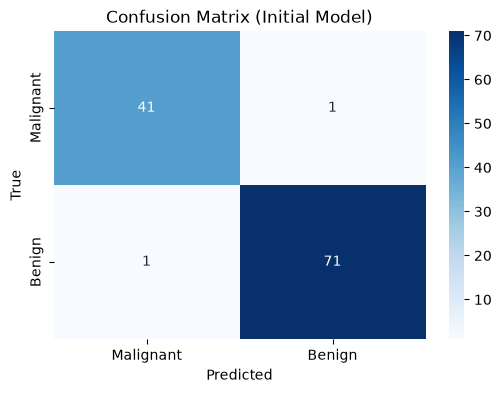

In [27]:
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
plt.title('Confusion Matrix (Initial Model)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

In [42]:
def plot_decision_boundary(X, y, model, kernel_name):
    h = 0.02  # Step size in the mesh
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

In [43]:
    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, cmap='Paired', alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='Set1', edgecolors='k')
    plt.title(f'Decision Boundary with {kernel_name} Kernel')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.show()

NameError: name 'xx' is not defined

<Figure size 800x600 with 0 Axes>

In [45]:
    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, cmap='Paired', alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='Set1', edgecolors='k')
    plt.title(f'Decision Boundary with {kernel_name} Kernel')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.show()

NameError: name 'xx' is not defined

<Figure size 800x600 with 0 Axes>

In [46]:
def plot_decision_boundary(X, y, model, kernel_name):
    h = 0.02  # Step size in the mesh
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    
    # Predict on mesh grid
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    # Plot decision boundary and points
    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, cmap='Paired', alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='Set1', edgecolors='k')
    plt.title(f'Decision Boundary with {kernel_name} Kernel')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.show()

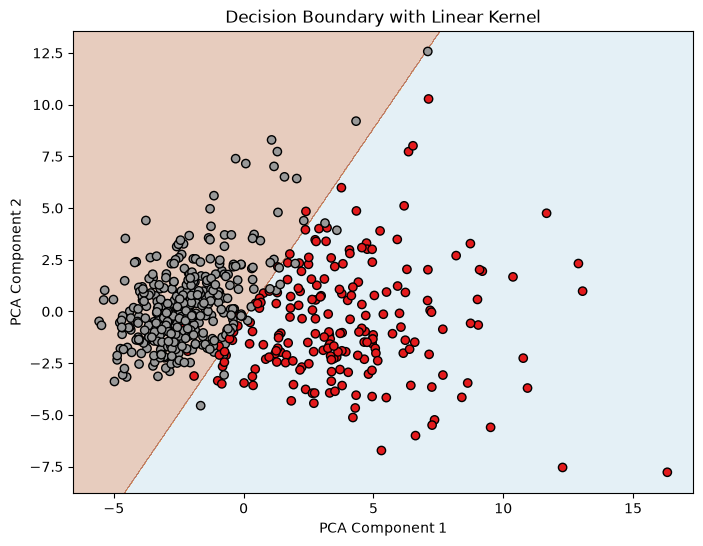

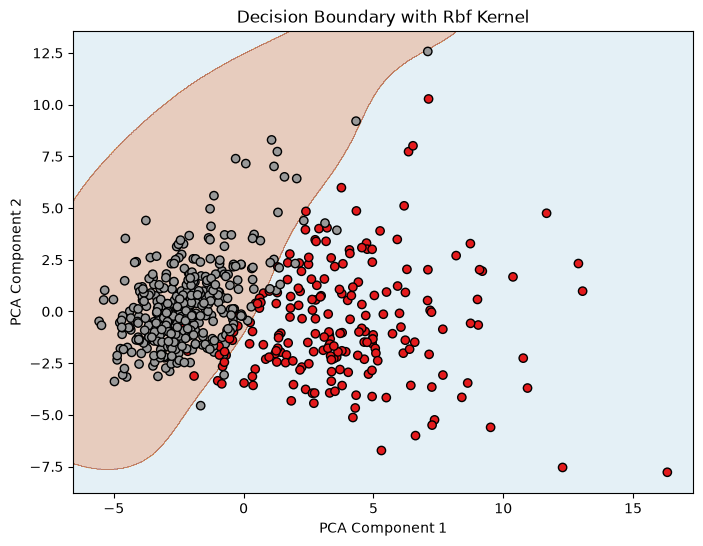

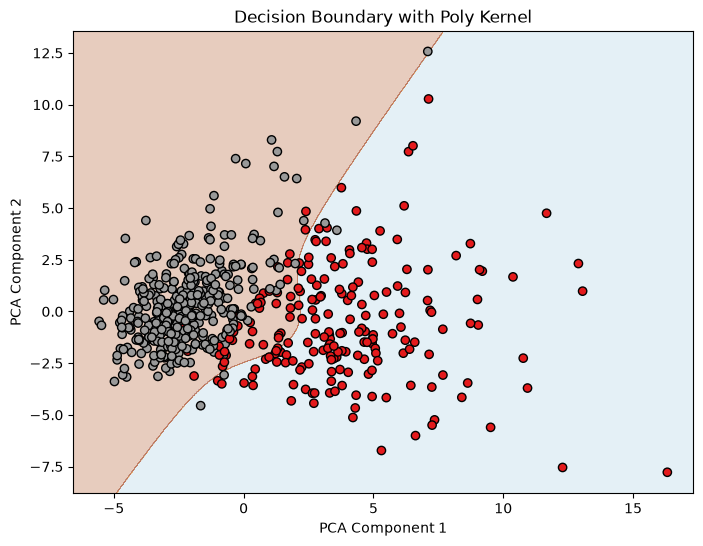

In [47]:
kernels = ['linear', 'rbf', 'poly']
for kernel in kernels:
    svc_vis = SVC(kernel=kernel, degree=3 if kernel == 'poly' else 1, random_state=42)
    svc_vis.fit(X_pca, y)
    plot_decision_boundary(X_pca, y, svc_vis, kernel.capitalize())

In [48]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 0.1, 1]
}

In [49]:
grid_search = GridSearchCV(SVC(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)
print("\nBest Parameters from Grid Search:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)


Best Parameters from Grid Search: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best Cross-Validation Accuracy: 0.9780219780219781


In [50]:
best_model = grid_search.best_estimator_
y_test_pred_tuned = best_model.predict(X_test)

In [51]:
test_accuracy_tuned = accuracy_score(y_test, y_test_pred_tuned)
print("\nTuned Model Evaluation:")
print(f"Test Accuracy (Tuned): {test_accuracy_tuned:.4f}")


Tuned Model Evaluation:
Test Accuracy (Tuned): 0.9825


In [52]:
print("\nClassification Report (Tuned Model, Test Set):")
print(classification_report(y_test, y_test_pred_tuned, target_names=['Malignant', 'Benign']))


Classification Report (Tuned Model, Test Set):
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



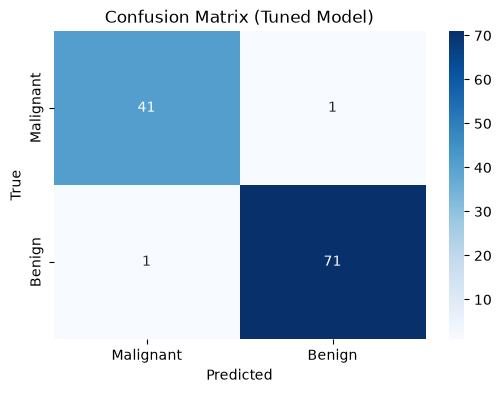

In [53]:
cm_tuned = confusion_matrix(y_test, y_test_pred_tuned)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Blues', xticklabels=['Malignant', 'Benign'], yticklabels=['Malignant', 'Benign'])
plt.title('Confusion Matrix (Tuned Model)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

In [55]:
sample = X_test.iloc[0:5]
sample_pred = best_model.predict(sample)
print("\nSample Predictions on Test Set (First 5 Samples):")
print("True Labels:", y_test[0:5])
print("Predicted Labels:", sample_pred)


Sample Predictions on Test Set (First 5 Samples):
True Labels: [0 1 0 1 0]
Predicted Labels: [0 1 0 1 0]


In [56]:
from joblib import dump
dump(best_model, 'svc_breast_cancer_model.joblib')
print("\nModel saved as 'svc_breast_cancer_model.joblib' for future use.")


Model saved as 'svc_breast_cancer_model.joblib' for future use.
